# Spectral clustering for image segmentation (graph construction): scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/cluster/plot_segmentation_toy.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/cluster/plot_segmentation_toy.html)).
A second section covers the `grid_to_graph` step of
`../scikit-learn/examples/cluster/plot_digits_agglomeration.py`
([gallery](https://scikit-learn.org/dev/auto_examples/cluster/plot_digits_agglomeration.html)).

**Scenario:** an image of touching noisy circles becomes a pixel graph with `image.img_to_graph(img, mask=mask)`;
edge weights are turned into affinities with `exp(-w / std(w))`, and `spectral_clustering` separates the
circles. The digits example builds a pixel-lattice connectivity with `grid_to_graph(8, 8)` for
`FeatureAgglomeration`.

**Adaptations:**
- **Size:** the circles image is 50x50 (centres and radii halved) instead of 100x100, so the dense graph stays
  small (Moxie returns `return_as="dense"` arrays; sparse COO output is deferred). The sklearn COO graph is
  compared through `.toarray()`.
- **Noise:** `np.random.RandomState(0)` replaces the unseeded global stream so both sides see the same image.
- **Affinity step in Mojo:** `graph.data = np.exp(-graph.data / graph.data.std())` acts on stored COO entries;
  on the dense Moxie graph the same entries are the diagonal plus non-zero off-diagonal weights (with Gaussian
  noise no stored edge weight is exactly zero; checked on the sklearn side).
- **GAPs:** `spectral_clustering` is not exported by the assembled `moxie.cluster` (import fails at compile time), and
  `FeatureAgglomeration(connectivity=...)` raises because connectivity-constrained linkage is deferred
  (cluster family). Both are proved by `--expect-fail` cells; the clustering labels are not compared.

**Determinism:** with the seeded noise the graph construction is deterministic, so graphs and affinities get
numerical parity. The reference `spectral_clustering` (ARPACK, k-means label assignment) is not compared.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("feature_extraction/plot_segmentation_toy")

## 1. scikit-learn (Python reference)

graph (654, 654) stored entries 3084 zero-valued stored entries 0


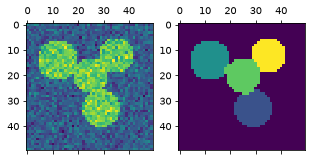

In [2]:
import numpy as np

l = 50
x, y = np.indices((l, l))

center1 = (14, 12)
center2 = (20, 25)
center3 = (33, 29)
center4 = (12, 35)

radius1, radius2, radius3, radius4 = 8, 7, 7.5, 7

circle1 = (x - center1[0]) ** 2 + (y - center1[1]) ** 2 < radius1**2
circle2 = (x - center2[0]) ** 2 + (y - center2[1]) ** 2 < radius2**2
circle3 = (x - center3[0]) ** 2 + (y - center3[1]) ** 2 < radius3**2
circle4 = (x - center4[0]) ** 2 + (y - center4[1]) ** 2 < radius4**2

img = circle1 + circle2 + circle3 + circle4
mask = img.astype(bool)
img = img.astype(float)
img += 1 + 0.2 * np.random.RandomState(0).randn(*img.shape)

from sklearn.feature_extraction import image

graph = image.img_to_graph(img, mask=mask)
sk_raw_graph = graph.toarray()
print("graph", graph.shape, "stored entries", graph.nnz, "zero-valued stored entries", int(np.sum(graph.data == 0)))
graph.data = np.exp(-graph.data / graph.data.std())
sk_affinity = graph.toarray()

import matplotlib.pyplot as plt
from sklearn.cluster import spectral_clustering

labels = spectral_clustering(graph, n_clusters=4, eigen_solver="arpack", random_state=0)
label_im = np.full(mask.shape, -1.0)
label_im[mask] = labels

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(5, 2.5), dpi=72)
axs[0].matshow(img)
axs[1].matshow(label_im)
plt.show()

In [3]:
from sklearn import datasets
from sklearn.feature_extraction.image import grid_to_graph

digits = datasets.load_digits()
images = digits.images
connectivity = grid_to_graph(*images[0].shape)
sk_connectivity = connectivity.toarray()
print(type(connectivity).__name__, connectivity.dtype, connectivity.shape)
sk_grid_3d = grid_to_graph(2, 3, 4).toarray()
nb.share(img=img, mask=mask)

coo_matrix int64 (64, 64)


## 2. Moxie (native Mojo)

In [4]:
%%mojo segmentation_graph
from std.math import exp, sqrt
from numojo import NDArray
from moxie.feature_extraction import image, grid_to_graph
from moxie_nb_io import load, save


def main() raises:
    var img = load("img")
    var mask = load[DType.bool]("mask")
    var graph = image.img_to_graph(img, mask=mask, return_as="dense")
    save("raw_graph", graph)
    var n = graph.shape[0]
    # Stored COO entries = diagonal plus non-zero off-diagonal weights.
    var total = 0.0
    var count = 0
    for i in range(n):
        for j in range(n):
            var v = graph.unsafe_get(i * n + j)
            if i == j or v != 0:
                total += v
                count += 1
    var mean = total / Float64(count)
    var squares = 0.0
    for i in range(n):
        for j in range(n):
            var v = graph.unsafe_get(i * n + j)
            if i == j or v != 0:
                squares += (v - mean) * (v - mean)
    var std = sqrt(squares / Float64(count))
    for i in range(n):
        for j in range(n):
            var v = graph.unsafe_get(i * n + j)
            if i == j or v != 0:
                graph.unsafe_set(i * n + j, exp(-v / std))
    save("affinity", graph)
    print("graph", n, "x", n, "stored entries", count)

    save("connectivity", grid_to_graph(8, 8, return_as="dense"))
    save("grid_3d", grid_to_graph(2, 3, 4, return_as="dense"))

graph 654 x 654 stored entries 3084


### Unsupported: spectral clustering, connectivity-constrained agglomeration and sparse graphs

Each cell must fail clearly.

In [5]:
%%mojo spectral_clustering --expect-fail
from moxie.cluster import spectral_clustering
from moxie.feature_extraction import grid_to_graph


def main() raises:
    var graph = grid_to_graph[DType.float64](4, 4, return_as="dense")
    _ = spectral_clustering(graph, n_clusters=2, eigen_solver="arpack")

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/feature_extraction/plot_segmentation_toy/spectral_clustering.mojo:1:27: error: package 'cluster' does not contain 'spectral_clustering'
from moxie.cluster import spectral_clustering
                          ^
mojo: error: failed to parse the provided Mojo source module



In [6]:
%%mojo feature_agglomeration_connectivity --expect-fail
from numojo import Shape, zeros
from moxie.cluster import FeatureAgglomeration
from moxie.feature_extraction import grid_to_graph


def main() raises:
    var connectivity = grid_to_graph[DType.float64](8, 8, return_as="dense")
    var X = zeros[DType.float64](Shape(5, 64))
    for i in range(X.size):
        X.unsafe_set(i, Float64(i % 17))
    var agglo = FeatureAgglomeration(connectivity=connectivity^, n_clusters=32)
    _ = agglo.fit(X)

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: connectivity-constrained linkage is deferred



In [7]:
%%mojo grid_to_graph_sparse_default --expect-fail
from moxie.feature_extraction import grid_to_graph


def main() raises:
    _ = grid_to_graph(8, 8)  # sklearn default return_as=sparse.coo_array

Expected failure (unsupported in Moxie):
exit status 1
stack trace was not collected. Enable stack trace collection with environment variable `MODULAR_DEBUG=stack-trace-on-error`
Unhandled exception caught during execution: NotImplementedError: sparse graphs deferred; select return_as='dense'



## 3. Side by side and parity

In [8]:
import moxie_nb

mx = nb.results["segmentation_graph"]
moxie_nb.side_by_side(sklearn=sk_affinity[:5, :5], moxie=mx["affinity"][:5, :5])
nb.compare("img_to_graph(img, mask=mask) dense", sk_raw_graph, mx["raw_graph"], exact=True,
           reason="pixel values on the diagonal, |difference| of Float64 neighbours; no accumulation")
nb.compare("affinity exp(-w / std(w))", sk_affinity, mx["affinity"], rtol=1e-11, atol=0,
           reason="notebook-side arithmetic, not library code: both std values agree to 1.5e-16 relative, but "
                  "Mojo std.math.exp differs from NumPy's libm exp by up to 1.4e-12 relative at arguments "
                  "near -3 (measured on this graph)")
nb.compare("grid_to_graph(8, 8) (digits connectivity)", sk_connectivity, mx["connectivity"], exact=True)
nb.compare("grid_to_graph dtype (int64)", np.array([str(connectivity.dtype)]), np.array([str(mx["connectivity"].dtype)]), exact=True)
nb.compare("grid_to_graph(2, 3, 4) (3-D lattice)", sk_grid_3d, mx["grid_3d"], exact=True)
nb.note("spectral_clustering", "GAP", "not exported by the assembled moxie.cluster (compile error: package cluster does not contain spectral_clustering); labels are not compared")
nb.note("FeatureAgglomeration(connectivity=grid_to_graph(...))", "GAP",
        "connectivity-constrained linkage is deferred in the cluster family")
nb.note("return_as=sparse.coo_array (default)", "GAP",
        "sparse graph output is deferred; return_as=\"dense\" must be passed explicitly")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
"img_to_graph(img, mask=mask) dense",PASS,"(654, 654)","(654, 654)",,,exact,0 mismatches,"pixel values on the diagonal, |difference| of Float64 neighbours; no accumulation"
affinity exp(-w / std(w)),PASS,"(654, 654)","(654, 654)",1.99e-13,1.41e-12,"rtol=1e-11, atol=0",,"notebook-side arithmetic, not library code: both std values agree to 1.5e-16 relative, but Mojo std.math.exp differs from NumPy's libm exp by up to 1.4e-12 relative at arguments near -3 (measured on this graph)"
"grid_to_graph(8, 8) (digits connectivity)",PASS,"(64, 64)","(64, 64)",,,exact,0 mismatches,
grid_to_graph dtype (int64),PASS,"(1,)","(1,)",,,exact,0 mismatches,
"grid_to_graph(2, 3, 4) (3-D lattice)",PASS,"(24, 24)","(24, 24)",,,exact,0 mismatches,
spectral_clustering,GAP,,,,,,not exported by the assembled moxie.cluster (compile error: package cluster does not contain spectral_clustering); labels are not compared,
FeatureAgglomeration(connectivity=grid_to_graph(...)),GAP,,,,,,connectivity-constrained linkage is deferred in the cluster family,
return_as=sparse.coo_array (default),GAP,,,,,,"sparse graph output is deferred; return_as=""dense"" must be passed explicitly",
